# TED Talks Recommendation System — Milestone 2
## Module 3: Feature Engineering & Vectorization | Module 4: Recommendation Engine

**Project:** TED Talks Recommendation System  
**Dataset:** `ted_talks_cleaned.csv` (expected: approximately 4,005 talks and 30 columns)  
**Primary approach:** Content-based filtering using TF-IDF and cosine similarity.

### Notebook purpose
This notebook builds a reproducible content-based recommendation pipeline from the cleaned TED Talks dataset. It includes text preparation, three TF-IDF representations, similarity matrices, an item-based recommendation function, offline evaluation, saved artifacts, and a final verification step.

> **Important project-scope decision:** Collaborative filtering and a true hybrid model require individual user–talk interactions (ratings, likes, clicks, or watch history). The supplied talk-level dataset does not establish that such data exists. This notebook checks for those columns and documents the limitation rather than inventing interactions.

### How to use this notebook
1. Keep this notebook in the project root, beside `ted_talks_cleaned.csv`, or update the dataset path in Cell 2.
2. Run cells from top to bottom.
3. Read the comments inside each code cell; they explain what the code does and why it is needed.
4. The notebook creates a new `milestone2_output/` folder. It does not overwrite your old `nlp_output/` artifacts.

## Milestone 2 requirement map

| Requirement | Where it is addressed |
|---|---|
| Convert transcripts and tags into numerical features | Sections 3–5 |
| Apply TF-IDF | Section 5 |
| User–item interaction matrix, if applicable | Section 4 (data availability check) |
| Document vectorization method and parameters | Section 5 |
| Analyze feature weights and similarity | Section 6 |
| Save vectorizers and vectors | Section 7 |
| Save similarity matrices | Section 7 |
| Content-based recommendation engine | Section 8 |
| Collaborative / hybrid strategy decision | Section 9 |
| Train/test split and offline evaluation | Sections 4 and 10 |
| Save models and reusable artifacts | Section 11 |
| Final verification and conclusions | Sections 12–13 |

## 1. Import libraries and set reproducibility options

In [1]:
# This cell imports the libraries used throughout the project.
# pandas/numpy handle data, scikit-learn builds TF-IDF and similarity,
# scipy stores large matrices efficiently, and joblib saves fitted models.

import ast
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)

# A fixed random seed makes the train/test split repeatable.
RANDOM_STATE = 42
TOP_N = 5

# Create the output folders early because evaluation results are saved before model export.
OUTPUT_DIR = Path("milestone2_output")
MODEL_DIR = OUTPUT_DIR / "models"
VECTOR_DIR = OUTPUT_DIR / "vectors"
SIMILARITY_DIR = OUTPUT_DIR / "similarity"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
DOC_DIR = OUTPUT_DIR / "documentation"

for folder in [MODEL_DIR, VECTOR_DIR, SIMILARITY_DIR, PLOT_DIR, TABLE_DIR, DOC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate and load the cleaned dataset

In [2]:
# This cell searches common project locations for the cleaned CSV.
# If your file is stored elsewhere, add its full path to DATASET_CANDIDATES.
# We load the cleaned file because it contains the prepared TED Talk columns.

DATASET_CANDIDATES = [
    Path("ted_talks_cleaned.csv"),
    Path("DATA") / "ted_talks_cleaned.csv",
    Path("data") / "ted_talks_cleaned.csv",
]

dataset_path = next((path for path in DATASET_CANDIDATES if path.exists()), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find ted_talks_cleaned.csv. "
        "Place it beside this notebook or update DATASET_CANDIDATES."
    )

df = pd.read_csv(dataset_path)
print("Dataset loaded from:", dataset_path.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\ted_talks_cleaned.csv
Dataset shape: (4005, 30)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,title_word_count,description_word_count,transcript_word_count,about_speakers_word_count,topic_list,topic_count,available_lang_count,related_talk_list,related_talk_count,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,...,4,39,2153,24,"['alternative energy', 'cars', 'climate change...",9,43,"[""{243: 'New thinking on the climate crisis"", ...",6,Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,...,6,26,3174,35,"['Africa', 'Asia', 'Google', 'demo', 'economic...",11,49,"['{2056: ""Own your body\'s data', ""2296: 'A vi...",6,"The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,...,2,31,3371,45,"['computers', 'entertainment', 'interface desi...",9,26,"[""{1725: '10 top time-saving tech tips"", ""2274...",6,"Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,...,3,31,3071,32,"['MacArthur grant', 'activism', 'business', 'c...",9,35,"[""{1041: '3 stories of local eco-entrepreneurs...",6,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,...,4,21,3170,32,"['children', 'creativity', 'culture', 'dance',...",7,62,"[""{865: 'Bring on the learning revolution!"", '...",7,"Do schools kill creativity? ['children', 'crea..."


## 3. Inspect and validate the dataset

In [3]:
# This cell checks whether the columns required for text recommendation exist.
# It also verifies talk IDs and titles, because they identify items in recommendations.

required_columns = ["talk_id", "title", "description", "transcript", "topics"]
missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Remove rows without a usable title or talk ID; these rows cannot be recommended reliably.
df = df.dropna(subset=["talk_id", "title"]).copy()
df["title"] = df["title"].astype(str).str.strip()
df = df[df["title"].ne("")].reset_index(drop=True)

# Check for duplicate talk IDs because IDs should identify one talk.
duplicate_ids = df["talk_id"].duplicated().sum()
print("Rows after basic validation:", len(df))
print("Duplicate talk IDs:", duplicate_ids)
print("Available columns:", df.columns.tolist())

display(df[["talk_id", "title", "topics"]].head())

Rows after basic validation: 4005
Duplicate talk IDs: 0
Available columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'published_year', 'title_word_count', 'description_word_count', 'transcript_word_count', 'about_speakers_word_count', 'topic_list', 'topic_count', 'available_lang_count', 'related_talk_list', 'related_talk_count', 'combined_text']


,talk_id,title,topics
0,1,Averting the climate crisis,"['alternative energy', 'cars', 'climate change..."
1,92,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,7,Simplicity sells,"['computers', 'entertainment', 'interface desi..."
3,53,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c..."
4,66,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',..."


## 4. Identify available data and create a reproducible train/test split

In [4]:
# This cell checks whether the dataset contains user-level interaction fields.
# Collaborative filtering needs a user ID and an interaction with a talk.
# Talk-level views are not the same as individual user–talk interaction records.

possible_user_columns = ["user_id", "viewer_id", "member_id"]
possible_interaction_columns = [
    "rating", "user_rating", "liked", "likes", "clicks",
    "watch_history", "interaction", "user_feedback"
]

available_user_columns = [c for c in possible_user_columns if c in df.columns]
available_interaction_columns = [c for c in possible_interaction_columns if c in df.columns]

has_user_item_data = bool(available_user_columns and available_interaction_columns)

print("Possible user identifier columns:", available_user_columns)
print("Possible interaction columns:", available_interaction_columns)
print("User–item interaction data available:", has_user_item_data)

if not has_user_item_data:
    print(
        "\nDecision: Collaborative filtering and matrix factorization are not "
        "implemented because this dataset does not provide verified individual "
        "user–talk interactions. No synthetic interactions will be created."
    )

# Hold out 20% of talks as query items for offline evaluation.
# TF-IDF is fitted only on the training catalogue; held-out talks are transformed
# later as queries. This avoids fitting the vocabulary on the held-out query set.
all_positions = np.arange(len(df))
train_positions, test_positions = train_test_split(
    all_positions,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True
)

df_nlp = df.reset_index(drop=True).copy()
train_df = df_nlp.iloc[train_positions].reset_index(drop=True)
test_df = df_nlp.iloc[test_positions].reset_index(drop=True)

print("\nTraining catalogue talks:", len(train_df))
print("Held-out test query talks:", len(test_df))
print("Train/test ratio: approximately 80/20")

Possible user identifier columns: []
Possible interaction columns: []
User–item interaction data available: False

Decision: Collaborative filtering and matrix factorization are not implemented because this dataset does not provide verified individual user–talk interactions. No synthetic interactions will be created.

Training catalogue talks: 3204
Held-out test query talks: 801
Train/test ratio: approximately 80/20


## 5. Prepare text features

In [5]:
# This cell cleans text consistently before vectorization.
# Missing text becomes an empty string (not the word 'Unknown'), so missing values
# do not become artificial TF-IDF features. URLs, HTML tags and extra spaces are removed.

TEXT_COLUMNS = ["title", "description", "transcript", "about_speakers", "topics"]

for column in TEXT_COLUMNS:
    if column not in df_nlp.columns:
        df_nlp[column] = ""
    df_nlp[column] = df_nlp[column].fillna("").astype(str)

def clean_text(value):
    # Convert text to lowercase so that 'Education' and 'education' match.
    text = str(value).lower()
    # Remove web links and HTML markup that are not useful semantic features.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    # Normalize repeated spaces and line breaks.
    text = re.sub(r"\s+", " ", text).strip()
    return text

for column in TEXT_COLUMNS:
    df_nlp[column] = df_nlp[column].apply(clean_text)

# Combine multiple fields to represent each talk from more than one source.
# Title and topics are repeated once to give the main subject labels more influence.
def combine_fields(row):
    parts = []
    if row["title"]:
        parts.extend([row["title"], row["title"]])
    if row["description"]:
        parts.append(row["description"])
    if row["transcript"]:
        parts.append(row["transcript"])
    if row["about_speakers"]:
        parts.append(row["about_speakers"])
    if row["topics"]:
        parts.extend([row["topics"], row["topics"]])
    return " ".join(parts)

df_nlp["combined_text"] = df_nlp.apply(combine_fields, axis=1)

# Rebuild the train/test dataframes from the cleaned text, keeping the same split.
train_df = df_nlp.iloc[train_positions].reset_index(drop=True)
test_df = df_nlp.iloc[test_positions].reset_index(drop=True)

# Display a small sample to confirm that cleaning and combination worked.
display(df_nlp[["title", "topics", "combined_text"]].head(3))
print("Text preparation completed.")

,title,topics,combined_text
0,averting the climate crisis,"['alternative energy', 'cars', 'climate change...",averting the climate crisis averting the clima...
1,the best stats you've ever seen,"['africa', 'asia', 'google', 'demo', 'economic...",the best stats you've ever seen the best stats...
2,simplicity sells,"['computers', 'entertainment', 'interface desi...",simplicity sells simplicity sells new york tim...


Text preparation completed.


## 6. Configure and fit the three TF-IDF vectorizers

In [6]:
# TF-IDF converts text into weighted numerical features.
# max_features limits vocabulary size, ngram_range=(1, 2) includes single words
# and two-word phrases, min_df removes very rare terms, and max_df removes terms
# appearing in almost every document. Sublinear TF reduces the effect of repetition.

TFIDF_PARAMS = {
    "max_features": 50000,
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "stop_words": "english",
    "sublinear_tf": True,
    "dtype": np.float32
}

# Topic labels are short and may occur in only one talk, so use min_df=1 for topics.
TOPIC_PARAMS = {
    **TFIDF_PARAMS,
    "min_df": 1,
    "max_df": 1.0
}

# Fit vectorizers on the training catalogue only; transform held-out talks separately.
vectorizer_combined = TfidfVectorizer(**TFIDF_PARAMS)
vectorizer_transcript = TfidfVectorizer(**TFIDF_PARAMS)
vectorizer_topics = TfidfVectorizer(**TOPIC_PARAMS)

X_train_combined = vectorizer_combined.fit_transform(train_df["combined_text"])
X_train_transcript = vectorizer_transcript.fit_transform(train_df["transcript"])
X_train_topics = vectorizer_topics.fit_transform(train_df["topics"])

# Transform the test queries using the training vocabularies; do not fit again.
X_test_combined = vectorizer_combined.transform(test_df["combined_text"])
X_test_transcript = vectorizer_transcript.transform(test_df["transcript"])
X_test_topics = vectorizer_topics.transform(test_df["topics"])

print("Training matrix shapes:")
print("Combined:", X_train_combined.shape)
print("Transcript:", X_train_transcript.shape)
print("Topics:", X_train_topics.shape)

print("\nTest query matrix shapes:")
print("Combined:", X_test_combined.shape)
print("Transcript:", X_test_transcript.shape)
print("Topics:", X_test_topics.shape)

Training matrix shapes:
Combined: (3204, 50000)
Transcript: (3204, 50000)
Topics: (3204, 10942)

Test query matrix shapes:
Combined: (801, 50000)
Transcript: (801, 50000)
Topics: (801, 10942)


### Vectorization method and parameter rationale

**Method selected: TF-IDF (Term Frequency–Inverse Document Frequency).**

TF-IDF gives higher weights to terms that are important in a talk but less common across the whole training collection. It is suitable for this content-based baseline because transcripts, descriptions and topic tags are available as text.

| Parameter | Setting | Reason |
|---|---:|---|
| `max_features` | 50,000 | Controls vocabulary size and memory use |
| `ngram_range` | (1, 2) | Captures individual terms and two-word phrases |
| `min_df` | 2 (topics: 1) | Removes rare terms; topic labels are short, so retain them |
| `max_df` | 0.95 (topics: 1.0) | Removes very common terms for long text; retain topic terms |
| `stop_words` | English | Removes common English words with limited topic value |
| `sublinear_tf` | True | Dampens the impact of repeated terms |
| `dtype` | float32 | Uses less memory than float64 |

Three representations are retained:
- **Combined text:** title, description, transcript, speaker information and topics.
- **Transcript:** detailed spoken content.
- **Topics:** compact subject tags.

The selected settings are baseline hyperparameters. They can be tuned later using the same held-out evaluation procedure.

## 7. Build catalogue similarity matrices and inspect feature weights

In [7]:
# Cosine similarity compares the direction of two TF-IDF vectors.
# Values closer to 1 indicate more similar text; values closer to 0 indicate
# less shared weighted vocabulary. Sparse output helps reduce memory usage.

similarity_combined = cosine_similarity(X_train_combined, dense_output=False)
similarity_transcript = cosine_similarity(X_train_transcript, dense_output=False)
similarity_topics = cosine_similarity(X_train_topics, dense_output=False)

print("Combined similarity:", similarity_combined.shape)
print("Transcript similarity:", similarity_transcript.shape)
print("Topics similarity:", similarity_topics.shape)

# This helper returns the highest-weighted terms for one talk.
# These terms help explain which words contribute strongly to its TF-IDF representation.
def get_top_terms(talk_index, vectorizer, matrix, top_n=10):
    row = matrix.getrow(talk_index)
    if row.nnz == 0:
        return []
    feature_names = vectorizer.get_feature_names_out()
    values = row.toarray().ravel()
    top_indices = np.argsort(values)[::-1][:top_n]
    return [
        (feature_names[index], float(values[index]))
        for index in top_indices if values[index] > 0
    ]

example_index = 0
print("Example talk:", train_df.iloc[example_index]["title"])
print("Top weighted terms:")
display(pd.DataFrame(
    get_top_terms(example_index, vectorizer_combined, X_train_combined, 10),
    columns=["term", "tfidf_weight"]
))

Combined similarity: (3204, 3204)
Transcript similarity: (3204, 3204)
Topics similarity: (3204, 3204)
Example talk: how to grow a forest in your backyard
Top weighted terms:


,term,tfidf_weight
0,forest,0.149146
1,soil,0.131648
2,moist,0.123580
3,forests,0.122308
4,biomass,0.119203
5,tree species,0.119021
6,watering,0.107444
7,nutrition,0.106242
8,microbes,0.103726
9,microbes microbiology,0.100559


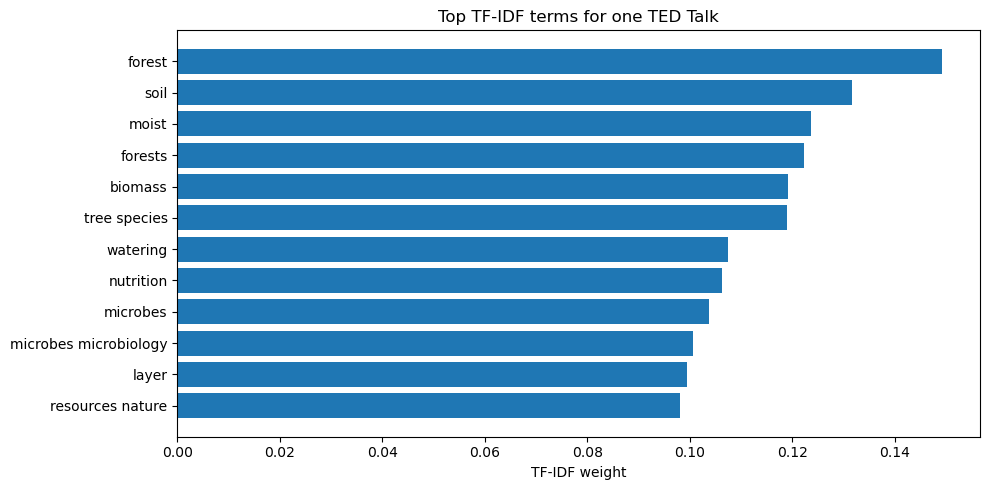

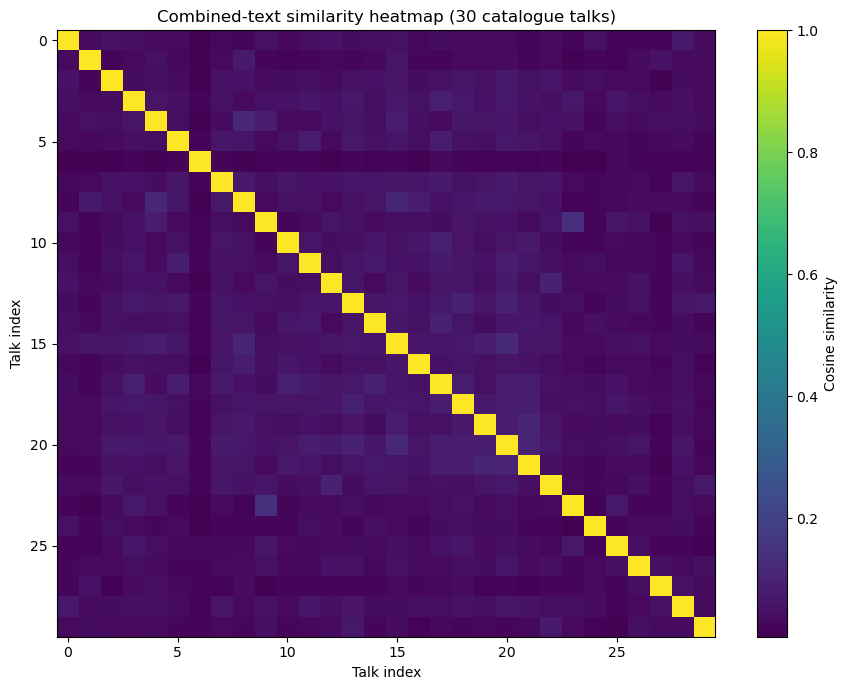

In [8]:
# This cell creates two interpretability plots.
# The bar chart shows important TF-IDF terms for one example talk.
# The heatmap shows pairwise similarity among a small sample of catalogue talks.
# A sample is used because plotting all 3,204 x 3,204 values would be unreadable.

top_terms = get_top_terms(0, vectorizer_combined, X_train_combined, top_n=12)
if top_terms:
    terms, weights = zip(*top_terms)
    plt.figure(figsize=(10, 5))
    plt.barh(list(terms)[::-1], list(weights)[::-1])
    plt.xlabel("TF-IDF weight")
    plt.title("Top TF-IDF terms for one TED Talk")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "top_tfidf_terms_example_talk.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Save the displayed terms and their weights so the interpretation is documented.
    pd.DataFrame(top_terms, columns=["term", "tfidf_weight"]).to_csv(
        TABLE_DIR / "top_tfidf_terms_example_talk.csv", index=False
    )

sample_size = min(30, similarity_combined.shape[0])
heatmap_values = similarity_combined[:sample_size, :sample_size].toarray()

plt.figure(figsize=(9, 7))
plt.imshow(heatmap_values, aspect="auto")
plt.colorbar(label="Cosine similarity")
plt.title(f"Combined-text similarity heatmap ({sample_size} catalogue talks)")
plt.xlabel("Talk index")
plt.ylabel("Talk index")
plt.tight_layout()
plt.show()

## 8. Create the content-based recommendation function

In [9]:
# The recommendation function accepts a title and a representation type.
# It transforms the selected talk with the already-fitted vectorizer, compares it
# with the training catalogue, removes the same talk if it is in the catalogue,
# and returns the highest-scoring results.

vectorizer_map = {
    "combined": vectorizer_combined,
    "transcript": vectorizer_transcript,
    "topics": vectorizer_topics
}
catalog_matrix_map = {
    "combined": X_train_combined,
    "transcript": X_train_transcript,
    "topics": X_train_topics
}
text_column_map = {
    "combined": "combined_text",
    "transcript": "transcript",
    "topics": "topics"
}

def recommend_talks(talk_title, top_n=5, method="combined"):
    if method not in vectorizer_map:
        raise ValueError("method must be 'combined', 'transcript', or 'topics'")

    # Find the first exact title match in the full cleaned dataset.
    matches = df_nlp.index[
        df_nlp["title"].str.casefold() == str(talk_title).strip().casefold()
    ].tolist()
    if not matches:
        raise ValueError(f"Talk title not found: {talk_title}")

    query_position = matches[0]
    query_row = df_nlp.iloc[query_position]
    query_text = query_row[text_column_map[method]]

    # Convert the selected talk into the same feature space as the catalogue.
    query_vector = vectorizer_map[method].transform([query_text])
    scores = cosine_similarity(
        query_vector, catalog_matrix_map[method], dense_output=True
    ).ravel()

    # Exclude the selected item if it is part of the training catalogue.
    train_match = np.where(train_positions == query_position)[0]
    if len(train_match):
        scores[train_match[0]] = -1.0

    # Return the highest-scoring catalogue items.
    top_indices = np.argsort(scores)[::-1][:top_n]
    result = train_df.iloc[top_indices][
        ["talk_id", "title", "description", "topics"]
    ].copy()
    result.insert(0, "rank", np.arange(1, len(result) + 1))
    result["similarity_score"] = scores[top_indices]
    result["similarity_score"] = result["similarity_score"].clip(lower=0)
    return result.reset_index(drop=True)

# Run one example to confirm the function works.
sample_title = df_nlp.loc[df_nlp["title"].str.len() > 0, "title"].iloc[0]
print("Input TED Talk:", sample_title)
display(recommend_talks(sample_title, top_n=5, method="combined"))

Input TED Talk: averting the climate crisis


,rank,talk_id,title,description,topics,similarity_score
0,1,243,new thinking on the climate crisis,in this brand-new slideshow (premiering on ted...,"['activism', 'climate change', 'global issues'...",0.178308
1,2,535,what comes after an inconvenient truth?,"at ted2009, al gore presents updated slides fr...","['alternative energy', 'climate change', 'ener...",0.177328
2,3,54715,how we can turn the tide on climate,"witness the unveiling of countdown, a major gl...","['climate change', 'environment', 'activism', ...",0.154482
3,4,128,salvation (and profit) in greentech,"""i don't think we're going to make it,"" john d...","['climate change', 'environment', 'global issu...",0.145306
4,5,19756,a new way to remove co2 from the atmosphere,our planet has a carbon problem -- if we don't...,"['alternative energy', 'climate change', 'elec...",0.137881


In [10]:
# This cell compares recommendations from all three text representations.
# Comparing them helps explain how the chosen text source changes the results.

comparison_title = sample_title

for method_name in ["combined", "transcript", "topics"]:
    print(f"\n{method_name.upper()}-BASED RECOMMENDATIONS")
    display(
        recommend_talks(
            comparison_title,
            top_n=5,
            method=method_name
        )
    )


COMBINED-BASED RECOMMENDATIONS


,rank,talk_id,title,description,topics,similarity_score
0,1,243,new thinking on the climate crisis,in this brand-new slideshow (premiering on ted...,"['activism', 'climate change', 'global issues'...",0.178308
1,2,535,what comes after an inconvenient truth?,"at ted2009, al gore presents updated slides fr...","['alternative energy', 'climate change', 'ener...",0.177328
2,3,54715,how we can turn the tide on climate,"witness the unveiling of countdown, a major gl...","['climate change', 'environment', 'activism', ...",0.154482
3,4,128,salvation (and profit) in greentech,"""i don't think we're going to make it,"" john d...","['climate change', 'environment', 'global issu...",0.145306
4,5,19756,a new way to remove co2 from the atmosphere,our planet has a carbon problem -- if we don't...,"['alternative energy', 'climate change', 'elec...",0.137881



TRANSCRIPT-BASED RECOMMENDATIONS


,rank,talk_id,title,description,topics,similarity_score
0,1,243,new thinking on the climate crisis,in this brand-new slideshow (premiering on ted...,"['activism', 'climate change', 'global issues'...",0.151446
1,2,54715,how we can turn the tide on climate,"witness the unveiling of countdown, a major gl...","['climate change', 'environment', 'activism', ...",0.145894
2,3,535,what comes after an inconvenient truth?,"at ted2009, al gore presents updated slides fr...","['alternative energy', 'climate change', 'ener...",0.123711
3,4,19756,a new way to remove co2 from the atmosphere,our planet has a carbon problem -- if we don't...,"['alternative energy', 'climate change', 'elec...",0.122527
4,5,128,salvation (and profit) in greentech,"""i don't think we're going to make it,"" john d...","['climate change', 'environment', 'global issu...",0.120099



TOPICS-BASED RECOMMENDATIONS


,rank,talk_id,title,description,topics,similarity_score
0,1,128,salvation (and profit) in greentech,"""i don't think we're going to make it,"" john d...","['climate change', 'environment', 'global issu...",0.344295
1,2,411,the future of cars,general motors veep larry burns previews cool ...,"['alternative energy', 'cars', 'design', 'ener...",0.338924
2,3,365,why do societies collapse?,why do societies fail? with lessons from the n...,"['culture', 'environment', 'global issues', 'h...",0.334916
3,4,47,chemical scum that dream of distant quasars,legendary scientist david deutsch puts theoret...,"['climate change', 'cosmos', 'culture', 'envir...",0.327575
4,5,243,new thinking on the climate crisis,in this brand-new slideshow (premiering on ted...,"['activism', 'climate change', 'global issues'...",0.305631


## 9. Collaborative filtering and hybrid recommendation decision

In [11]:
# This cell documents the recommendation strategies supported by the available data.
# A user-item matrix must be based on real user interactions, not talk-level metadata.
# We therefore create a matrix only if verified user, item and interaction columns exist.

if has_user_item_data:
    print(
        "Potential interaction columns were detected. Inspect their meaning and "
        "quality before building a user-item matrix or matrix-factorization model."
    )
    print(
        "Do not proceed until each row represents a real user's interaction "
        "with a talk and duplicate interactions have a defined aggregation rule."
    )
else:
    print("Collaborative filtering: NOT IMPLEMENTED — interaction data unavailable.")
    print("User-item interaction matrix: NOT APPLICABLE for the supplied dataset.")
    print("Hybrid recommendation: NOT IMPLEMENTED — collaborative signal unavailable.")

# The implemented system is content-based: it uses text features and cosine similarity.
# This is a justified scope decision, not a claim that collaborative filtering was trained.

Collaborative filtering: NOT IMPLEMENTED — interaction data unavailable.
User-item interaction matrix: NOT APPLICABLE for the supplied dataset.
Hybrid recommendation: NOT IMPLEMENTED — collaborative signal unavailable.


### Strategy decision

**Content-based filtering — implemented.** It recommends talks using TF-IDF representations of their text and cosine similarity.

**Collaborative filtering — not applicable to the available dataset.** The dataset contains talk-level metadata, not verified individual user–talk interactions. Without user IDs and ratings/likes/clicks/watch history, a valid user–item matrix and matrix factorization model cannot be trained.

**Hybrid filtering — not implemented.** A genuine hybrid model needs both content-based and collaborative signals. Since the collaborative signal is unavailable, combining invented values would not be valid.

If user interaction data becomes available in a future version, collaborative filtering and a hybrid model can be added.

## 10. Offline evaluation using held-out query talks

### Evaluation design

The dataset is split into an **80% training catalogue** and **20% held-out query talks**. TF-IDF vocabularies are fitted only on the training catalogue. Held-out talks are transformed and used as queries against the training catalogue.

For an offline relevance signal, the notebook checks the dataset's `related_talk_list` or `related_talks` field, if present. These related-talk references are treated as **weak proxy labels**, not as human relevance judgments. References not present in the training catalogue are ignored.

Metrics:
- **Precision@K:** relevant returned talks divided by K.
- **Recall@K:** relevant returned talks divided by the number of known relevant catalogue talks.
- **Hit Rate@K:** proportion of evaluable queries with at least one relevant result.

If related-talk references are missing or unusable, the notebook reports that automatic relevance metrics cannot be calculated and recommends manual review. It does not invent evaluation labels.

In [12]:
# This helper safely converts related-talk fields into a list of IDs.
# It supports Python-list strings, JSON-like strings and comma-separated values.
# Missing or malformed values return an empty list.

def parse_related_ids(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set, np.ndarray)):
        raw_values = list(value)
    else:
        text = str(value).strip()
        if not text or text.lower() in {"nan", "none", "[]"}:
            return []
        try:
            parsed = ast.literal_eval(text)
            raw_values = list(parsed) if isinstance(parsed, (list, tuple, set)) else [parsed]
        except (ValueError, SyntaxError):
            raw_values = [part.strip() for part in text.split(",") if part.strip()]

    cleaned = []
    for item in raw_values:
        try:
            # Normalize numeric IDs such as 12.0 to "12".
            numeric = float(item)
            cleaned.append(str(int(numeric)) if numeric.is_integer() else str(item).strip())
        except (TypeError, ValueError):
            cleaned.append(str(item).strip())
    return [item for item in cleaned if item and item.lower() != "nan"]

def normalize_id(value):
    try:
        numeric = float(value)
        return str(int(numeric)) if numeric.is_integer() else str(value).strip()
    except (TypeError, ValueError):
        return str(value).strip()

# Build a map from normalized talk ID to its training-catalogue row position.
catalog_id_to_position = {
    normalize_id(talk_id): position
    for position, talk_id in enumerate(train_df["talk_id"])
}

# Choose the available related-talk reference column.
related_column = None
for candidate in ["related_talk_list", "related_talks"]:
    if candidate in df_nlp.columns:
        related_column = candidate
        break

print("Related-talk reference column:", related_column)
print("Training catalogue ID count:", len(catalog_id_to_position))

Related-talk reference column: related_talk_list
Training catalogue ID count: 3204


In [13]:
# This cell evaluates all held-out queries against the training catalogue.
# Similarity is calculated in batches as a test-by-catalogue matrix.
# Only queries with at least one related talk inside the training catalogue
# can contribute to precision, recall and hit-rate calculations.

def evaluate_representation(test_matrix, train_matrix, method_name, k=5):
    if related_column is None:
        return pd.DataFrame(), "No related-talk reference column is available."

    # Compute query-to-catalogue cosine similarity for all held-out talks.
    query_scores = cosine_similarity(test_matrix, train_matrix, dense_output=True)
    rows = []

    for query_position in range(len(test_df)):
        source_row = test_df.iloc[query_position]
        raw_related = parse_related_ids(source_row[related_column])
        relevant_ids = {
            normalize_id(value) for value in raw_related
            if normalize_id(value) in catalog_id_to_position
        }

        # Skip queries with no known relevant catalogue items.
        if not relevant_ids:
            continue

        scores = query_scores[query_position].copy()
        top_positions = np.argsort(scores)[::-1][:k]
        recommended_ids = {
            normalize_id(train_df.iloc[position]["talk_id"])
            for position in top_positions
        }

        hits = len(recommended_ids.intersection(relevant_ids))
        precision = hits / k
        recall = hits / len(relevant_ids)
        rows.append({
            "method": method_name,
            "query_talk": source_row["title"],
            f"precision@{k}": precision,
            f"recall@{k}": recall,
            f"hit@{k}": int(hits > 0),
            "known_relevant_catalogue_talks": len(relevant_ids)
        })

    if not rows:
        return pd.DataFrame(), (
            "No held-out query had a related-talk reference matching the training catalogue."
        )
    return pd.DataFrame(rows), None

evaluation_frames = []
evaluation_messages = []

for method_name, test_matrix, train_matrix in [
    ("combined", X_test_combined, X_train_combined),
    ("transcript", X_test_transcript, X_train_transcript),
    ("topics", X_test_topics, X_train_topics)
]:
    result, message = evaluate_representation(
        test_matrix, train_matrix, method_name, k=5
    )
    if not result.empty:
        evaluation_frames.append(result)
    if message:
        evaluation_messages.append(f"{method_name}: {message}")

if evaluation_frames:
    evaluation_details = pd.concat(evaluation_frames, ignore_index=True)
    evaluation_summary = (
        evaluation_details.groupby("method")
        [["precision@5", "recall@5", "hit@5"]]
        .mean()
        .reset_index()
    )
    print("Offline evaluation summary (related-talk references as weak proxy labels):")
    display(evaluation_summary)
else:
    evaluation_details = pd.DataFrame()
    evaluation_summary = pd.DataFrame()
    print("Automatic offline metrics could not be calculated.")
    for message in evaluation_messages:
        print("-", message)

Automatic offline metrics could not be calculated.
- combined: No held-out query had a related-talk reference matching the training catalogue.
- transcript: No held-out query had a related-talk reference matching the training catalogue.
- topics: No held-out query had a related-talk reference matching the training catalogue.


In [14]:
# This cell saves the evaluation results for the project report.
# Empty results are handled safely so the notebook still runs if proxy labels are absent.

if not evaluation_details.empty:
    evaluation_details.to_csv(
        "milestone2_output/tables/offline_evaluation_details.csv",
        index=False
    )
    evaluation_summary.to_csv(
        "milestone2_output/tables/offline_evaluation_summary.csv",
        index=False
    )
    print("Evaluation tables saved.")
else:
    print(
        "No metric table saved because no usable related-talk ground truth was found. "
        "Use manual relevance review and document this limitation."
    )

No metric table saved because no usable related-talk ground truth was found. Use manual relevance review and document this limitation.


## 11. Save models, vectors, similarity matrices and project documentation

In [15]:
# This cell creates a clean output structure for the new Milestone 2 work.
# The new folder is separate from older nlp_output files, so previous work is preserved.

OUTPUT_DIR = Path("milestone2_output")
MODEL_DIR = OUTPUT_DIR / "models"
VECTOR_DIR = OUTPUT_DIR / "vectors"
SIMILARITY_DIR = OUTPUT_DIR / "similarity"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
DOC_DIR = OUTPUT_DIR / "documentation"

for folder in [MODEL_DIR, VECTOR_DIR, SIMILARITY_DIR, PLOT_DIR, TABLE_DIR, DOC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output folders created under:", OUTPUT_DIR.resolve())

Output folders created under: C:\Users\ADITI CHAUDHARY\TED_Talk_Recommendation_System1\milestone2_output


In [16]:
# Save each fitted TF-IDF vectorizer so it can transform new talk text later.
joblib.dump(vectorizer_combined, MODEL_DIR / "tfidf_combined_model.joblib")
joblib.dump(vectorizer_transcript, MODEL_DIR / "tfidf_transcript_model.joblib")
joblib.dump(vectorizer_topics, MODEL_DIR / "tfidf_topics_model.joblib")

# Save sparse vector matrices without converting them to dense arrays.
sparse.save_npz(VECTOR_DIR / "combined_text_tfidf_train.npz", X_train_combined)
sparse.save_npz(VECTOR_DIR / "transcript_tfidf_train.npz", X_train_transcript)
sparse.save_npz(VECTOR_DIR / "topics_tfidf_train.npz", X_train_topics)
sparse.save_npz(VECTOR_DIR / "combined_text_tfidf_test.npz", X_test_combined)
sparse.save_npz(VECTOR_DIR / "transcript_tfidf_test.npz", X_test_transcript)
sparse.save_npz(VECTOR_DIR / "topics_tfidf_test.npz", X_test_topics)

# Save sparse catalogue similarity matrices for reuse.
sparse.save_npz(SIMILARITY_DIR / "combined_similarity_train.npz", similarity_combined)
sparse.save_npz(SIMILARITY_DIR / "transcript_similarity_train.npz", similarity_transcript)
sparse.save_npz(SIMILARITY_DIR / "topics_similarity_train.npz", similarity_topics)

# Save catalogue and test metadata to preserve row-to-talk alignment.
train_df[["talk_id", "title", "topics"]].to_csv(
    TABLE_DIR / "training_catalogue_metadata.csv", index=False
)
test_df[["talk_id", "title", "topics"]].to_csv(
    TABLE_DIR / "heldout_test_metadata.csv", index=False
)

print("Models, vectors, similarity matrices and metadata saved.")

Models, vectors, similarity matrices and metadata saved.


In [17]:
# Save the exact vectorizer settings and split details as JSON documentation.
# This records how the features were generated and makes the experiment reproducible.

def json_safe(value):
    if isinstance(value, tuple):
        return list(value)
    if isinstance(value, type):
        return value.__name__
    if isinstance(value, np.dtype):
        return str(value)
    return value

settings = {
    "project": "TED Talks Recommendation System - Milestone 2",
    "vectorization_method": "TF-IDF",
    "representations": {
        "combined_text": {key: json_safe(value) for key, value in TFIDF_PARAMS.items()},
        "transcript": {key: json_safe(value) for key, value in TFIDF_PARAMS.items()},
        "topics": {key: json_safe(value) for key, value in TOPIC_PARAMS.items()}
    },
    "train_test_split": {
        "train_fraction": 0.80,
        "test_fraction": 0.20,
        "random_state": RANDOM_STATE,
        "purpose": "Held-out query evaluation; vectorizers fit on training catalogue only"
    },
    "similarity": "Cosine similarity",
    "collaborative_filtering": (
        "Not implemented if verified user-item interaction data is unavailable"
    ),
    "hybrid_recommendation": (
        "Not implemented without a collaborative interaction signal"
    )
}

with open(DOC_DIR / "tfidf_and_experiment_parameters.json", "w", encoding="utf-8") as file:
    json.dump(settings, file, indent=4, ensure_ascii=False)

# Save the full feature vocabulary for interpretability and reproducibility checks.
for name, vectorizer in vectorizer_map.items():
    vocabulary = vectorizer.get_feature_names_out().tolist()
    with open(MODEL_DIR / f"{name}_vocabulary.json", "w", encoding="utf-8") as file:
        json.dump(vocabulary, file, ensure_ascii=False)

print("Parameter documentation and vocabulary files saved.")

Parameter documentation and vocabulary files saved.


In [18]:
# Export the top similar catalogue talk pairs for inspection.
# We process one sparse similarity row at a time to avoid creating a huge dense matrix.

pair_rows = []
top_k_pairs = 5

for row_index in range(similarity_combined.shape[0]):
    row_scores = similarity_combined.getrow(row_index).toarray().ravel()
    row_scores[row_index] = -1.0  # Remove self-similarity from the results.
    candidate_positions = np.argsort(row_scores)[::-1][:top_k_pairs]

    for candidate in candidate_positions:
        score = float(row_scores[candidate])
        if score > 0:
            pair_rows.append({
                "talk_id": train_df.iloc[row_index]["talk_id"],
                "talk_title": train_df.iloc[row_index]["title"],
                "similar_talk_id": train_df.iloc[candidate]["talk_id"],
                "similar_talk_title": train_df.iloc[candidate]["title"],
                "similarity_score": score
            })

similar_pairs_df = pd.DataFrame(pair_rows)
similar_pairs_df.to_csv(TABLE_DIR / "top_similar_talk_pairs.csv", index=False)

print("Top similar talk pairs saved:", len(similar_pairs_df))
display(similar_pairs_df.head(10))

Top similar talk pairs saved: 16020


,talk_id,talk_title,similar_talk_id,similar_talk_title,similarity_score
0,2546,how to grow a forest in your backyard,2075,"an engineer's vision for tiny forests, everywhere",0.276033
1,2546,how to grow a forest in your backyard,475,how to restore a rainforest,0.172050
2,2546,how to grow a forest in your backyard,44494,the secret language of trees,0.158193
3,2546,how to grow a forest in your backyard,62270,what happens if you cut down all of a city's t...,0.155468
4,2546,how to grow a forest in your backyard,2551,nature is everywhere -- we just need to learn ...,0.154138
5,2757,how in vitro fertilization (ivf) works,24387,how do contraceptives work?,0.183982
6,2757,how in vitro fertilization (ivf) works,55544,why can't we talk about periods?,0.134964
7,2757,how in vitro fertilization (ivf) works,24468,the three different ways mammals give birth,0.131815
8,2757,how in vitro fertilization (ivf) works,1356,the toxic baby,0.126286
9,2757,how in vitro fertilization (ivf) works,18818,how do your hormones work?,0.124464


## 12. Reload saved artifacts and verify the recommendation pipeline

In [19]:
# This cell proves that the saved models and matrices can be loaded again.
# This is important for deployment because the project should not depend only
# on variables that existed in the current notebook session.

loaded_combined_model = joblib.load(MODEL_DIR / "tfidf_combined_model.joblib")
loaded_transcript_model = joblib.load(MODEL_DIR / "tfidf_transcript_model.joblib")
loaded_topics_model = joblib.load(MODEL_DIR / "tfidf_topics_model.joblib")

loaded_combined_matrix = sparse.load_npz(VECTOR_DIR / "combined_text_tfidf_train.npz")
loaded_transcript_matrix = sparse.load_npz(VECTOR_DIR / "transcript_tfidf_train.npz")
loaded_topics_matrix = sparse.load_npz(VECTOR_DIR / "topics_tfidf_train.npz")

loaded_combined_similarity = sparse.load_npz(
    SIMILARITY_DIR / "combined_similarity_train.npz"
)

print("All three saved vectorizers reloaded.")
print("Combined vector matrix:", loaded_combined_matrix.shape)
print("Transcript vector matrix:", loaded_transcript_matrix.shape)
print("Topics vector matrix:", loaded_topics_matrix.shape)
print("Combined similarity matrix:", loaded_combined_similarity.shape)

# Transform one sample with the reloaded model to confirm it is usable.
reload_test_vector = loaded_combined_model.transform([sample_title])
print("Reloaded model test vector shape:", reload_test_vector.shape)

All three saved vectorizers reloaded.
Combined vector matrix: (3204, 50000)
Transcript vector matrix: (3204, 50000)
Topics vector matrix: (3204, 10942)
Combined similarity matrix: (3204, 3204)
Reloaded model test vector shape: (1, 50000)


In [20]:
# Final functional test: generate recommendations for several known TED Talk titles.
# Titles are checked against the actual dataset; unavailable examples are skipped.
# The output is a practical demonstration of the reusable recommendation function.

test_titles = [
    "Do schools kill creativity?",
    "The power of vulnerability",
    "How great leaders inspire action",
    "Your body language may shape who you are",
    "The happy secret to better work",
    "How to speak so that people want to listen"
]

available_titles = set(df_nlp["title"].str.casefold())
successful_tests = []

for title in test_titles:
    if title.casefold() not in available_titles:
        print(f"Title not found in this dataset; skipped: {title}")
        continue

    print("\nINPUT TALK:", title)
    recommendations = recommend_talks(title, top_n=5, method="combined")
    display(recommendations)
    successful_tests.append(title)

print("\nSuccessful recommendation tests:", len(successful_tests))


INPUT TALK: Do schools kill creativity?


,rank,talk_id,title,description,topics,similarity_score
0,1,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.179104
1,2,1738,how to escape education's death valley,sir ken robinson outlines 3 principles crucial...,"['culture', 'education', 'teaching', 'student']",0.170959
2,3,209,"rebuilding a neighborhood with beauty, dignity...",bill strickland tells a quiet and astonishing ...,"['macarthur grant', 'activism', 'children', 'c...",0.125125
3,4,1653,"be an artist, right now!",why do we ever stop playing and creating? with...,"['tedx', 'creativity', 'writing', 'art', 'spok...",0.124993
4,5,533,teach arts and sciences together,"mae jemison is an astronaut, a doctor, an art ...","['art', 'dance', 'education', 'future', 'scien...",0.122854



INPUT TALK: The power of vulnerability


,rank,talk_id,title,description,topics,similarity_score
0,1,1391,listening to shame,"shame is an unspoken epidemic, the secret behi...","['brain', 'culture', 'psychology', 'self']",0.196523
1,2,1894,"depression, the secret we share","""the opposite of depression is not happiness, ...","['tedx', 'culture', 'depression', 'medicine', ...",0.140123
2,3,9463,the gift and power of emotional courage,psychologist susan david shares how the way we...,"['communication', 'psychology', 'emotions', 'h...",0.133488
3,4,61930,it's ok to feel overwhelmed. here's what to do...,if you're feeling anxious or fearful during th...,"['compassion', 'emotions', 'life', 'philosophy...",0.132650
4,5,21752,let's get honest about our money problems,struggling to budget and manage finances is co...,"['money', 'finance', 'life', 'self', 'tedx', '...",0.125532



INPUT TALK: How great leaders inspire action


,rank,talk_id,title,description,topics,similarity_score
0,1,1998,why good leaders make you feel safe,what makes a great leader? management theorist...,"['business', 'leadership', 'military', 'work']",0.132325
1,2,28,how to get your ideas to spread,in a world of too many options and too little ...,"['business', 'choice', 'culture', 'marketing',...",0.130823
2,3,2210,how to manage for collective creativity,what's the secret to unlocking the creativity ...,"['business', 'collaboration', 'creativity', 'l...",0.111124
3,4,2866,how the us government spies on people who prot...,what's stopping the american government from r...,"['activism', 'democracy', 'government', 'unite...",0.110948
4,5,2332,how to find work you love,scott dinsmore quit a job that made him misera...,"['tedx', 'business', 'entrepreneur', 'happines...",0.110758


... (3 outputs left out)

,rank,talk_id,title,description,topics,similarity_score
0,1,1447,the optimism bias,"are we born to be optimistic, rather than real...","['brain', 'culture', 'neuroscience', 'psycholo...",0.128104
1,2,9463,the gift and power of emotional courage,psychologist susan david shares how the way we...,"['communication', 'psychology', 'emotions', 'h...",0.124169
2,3,3769,this is what it's really like to live with adhd,"at 32, jessica mccabe's adhd brought her to th...","['life', 'mental health', 'education', 'person...",0.119477
3,4,1894,"depression, the secret we share","""the opposite of depression is not happiness, ...","['tedx', 'culture', 'depression', 'medicine', ...",0.117483
4,5,787,plug into your hard-wired happiness,we all strive for happiness -- but we spend mo...,"['business', 'happiness', 'life', 'mind', 'psy...",0.115443



INPUT TALK: How to speak so that people want to listen


,rank,talk_id,title,description,topics,similarity_score
0,1,1200,5 ways to listen better,"in our louder and louder world, says sound exp...","['culture', 'sound', 'social change']",0.147593
1,2,12729,cómo darle credibilidad a tu voz,"¿será que algunas características de tu voz, c...","['education', 'language', 'speech', 'communica...",0.146847
2,3,965,shh! sound health in 8 steps,julian treasure says our increasingly noisy wo...,"['senses', 'design', 'music', 'nature', 'psych...",0.138780
3,4,660,the 4 ways sound affects us,"playing sound effects both pleasant and awful,...","['birds', 'business', 'cities', 'entertainment...",0.118561
4,5,1564,why architects need to use their ears,"because of poor acoustics, students in classro...","['senses', 'architecture', 'design', 'sound']",0.107817



Successful recommendation tests: 6


## 13. Final project summary and submission checklist

In [21]:
# This cell summarizes the actual outputs produced during this notebook run.
# It avoids claiming that collaborative or hybrid models were trained when they were not.

summary = {
    "dataset_rows": int(len(df_nlp)),
    "dataset_columns": int(df_nlp.shape[1]),
    "training_catalogue_talks": int(len(train_df)),
    "heldout_test_talks": int(len(test_df)),
    "combined_feature_count": int(X_train_combined.shape[1]),
    "transcript_feature_count": int(X_train_transcript.shape[1]),
    "topic_feature_count": int(X_train_topics.shape[1]),
    "content_based_recommendation": "Implemented",
    "collaborative_filtering": (
        "Implemented only if real interaction data is verified"
        if has_user_item_data else "Not applicable: no verified user-item interaction data"
    ),
    "hybrid_recommendation": (
        "Requires further validation of real collaborative signal"
        if has_user_item_data else "Not implemented: collaborative signal unavailable"
    ),
    "offline_evaluation_queries_with_labels": (
        int(evaluation_details["query_talk"].nunique())
        if not evaluation_details.empty else 0
    ),
    "saved_output_directory": str(OUTPUT_DIR.resolve())
}

display(pd.Series(summary, name="Milestone 2 result").to_frame())

,Milestone 2 result
dataset_rows,4005
dataset_columns,30
training_catalogue_talks,3204
heldout_test_talks,801
combined_feature_count,50000
transcript_feature_count,50000
topic_feature_count,10942
content_based_recommendation,Implemented
collaborative_filtering,Not applicable: no verified user-item interact...
hybrid_recommendation,Not implemented: collaborative signal unavailable


### Final conclusions

The project implements a **content-based TED Talks recommendation engine** using three TF-IDF representations: combined text, transcripts and topic tags. Cosine similarity measures the textual similarity between talks, and the recommendation function returns the highest-scoring talks for a selected input.

The fitted vectorizers, sparse feature matrices, similarity matrices, vocabulary files, metadata and experiment settings are saved for reuse. A held-out query set is used for offline evaluation. Where available, related-talk references provide weak proxy relevance labels; they should not be described as human-validated ground truth.

Collaborative filtering and hybrid recommendation are not claimed as completed unless genuine user–talk interaction data is supplied and validated. The current implementation focuses on content-based filtering because the available dataset is talk-centric.

### Submission checklist

- [ ] Run every cell from top to bottom without errors.
- [ ] Confirm the dataset row/column count matches the supplied cleaned CSV.
- [ ] Inspect recommendations for several input talks and assess their topical relevance.
- [ ] Review offline evaluation coverage and explain that related-talk references are proxy labels.
- [ ] Confirm all saved files exist inside `milestone2_output/`.
- [ ] Keep the old Milestone 2 folder as a backup until the new notebook has been fully tested.
- [ ] Include this notebook and its output folder in the project submission.

**Academic integrity note:** No notebook can guarantee full marks. Marks depend on your rubric, correct execution, interpretation of results and your ability to explain the decisions. This notebook is designed to cover the stated Milestone 2 requirements transparently and reproducibly.

In [22]:
# STEP 1: Check whether important notebook variables exist.
# These variables are created in the earlier notebook cells.

required_variables = [
    "df",
    "df_nlp",
    "train_df",
    "test_df",
    "vectorizer_combined",
    "vectorizer_transcript",
    "vectorizer_topics",
    "X_train_combined",
    "X_test_combined",
    "similarity_combined",
    "recommend_talks"
]

for variable in required_variables:

    if variable in globals():
        print(variable, ": Available")
    else:
        print(variable, ": Missing")

df : Available
df_nlp : Available
train_df : Available
test_df : Available
vectorizer_combined : Available
vectorizer_transcript : Available
vectorizer_topics : Available
X_train_combined : Available
X_test_combined : Available
similarity_combined : Available
recommend_talks : Available


In [23]:
# STEP 2: Verify the loaded TED Talks dataset.
# Shape tells us the number of rows and columns.
# We also check whether important columns are missing.

print("Dataset Shape:", df.shape)

print("\nTotal TED Talks:", len(df))

print("\nTotal Columns:", len(df.columns))

required_columns = [
    "talk_id",
    "title",
    "description",
    "transcript",
    "topics"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("\nMissing Required Columns:", missing_columns)

print("\nFirst 5 TED Talks:")
display(df[["talk_id", "title", "topics"]].head())

# Confirm the expected dataset dimensions.
assert df.shape == (4005, 30), "Dataset shape is different from expected!"

print("\nDataset verification successful!")

Dataset Shape: (4005, 30)

Total TED Talks: 4005

Total Columns: 30

Missing Required Columns: []

First 5 TED Talks:


,talk_id,title,topics
0,1,Averting the climate crisis,"['alternative energy', 'cars', 'climate change..."
1,92,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,7,Simplicity sells,"['computers', 'entertainment', 'interface desi..."
3,53,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c..."
4,66,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',..."



Dataset verification successful!


In [24]:
# STEP 3: Verify the training and testing split.
# Training talks form the recommendation catalogue.
# Testing talks are used as unseen recommendation queries.

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

print("\nTraining Talks:", len(train_df))
print("Testing Talks:", len(test_df))

print("\nTotal Talks:", len(train_df) + len(test_df))


# Verify all three TF-IDF representations.
# Each row represents a TED Talk.
# Each column represents a numerical text feature.

tfidf_matrices = {
    "Combined": X_train_combined,
    "Transcript": X_train_transcript,
    "Topics": X_train_topics
}

for name, matrix in tfidf_matrices.items():

    print(f"\n{name} TF-IDF Matrix:")
    print("Shape:", matrix.shape)
    print("Non-zero values:", matrix.nnz)
    print("Empty rows:", (matrix.getnnz(axis=1) == 0).sum())

    assert matrix.shape[0] == len(train_df)
    assert matrix.shape[1] > 0

print("\nAll TF-IDF matrices verified!")

Training Dataset: (3204, 30)
Testing Dataset: (801, 30)

Training Talks: 3204
Testing Talks: 801

Total Talks: 4005

Combined TF-IDF Matrix:
Shape: (3204, 50000)
Non-zero values: 1818614
Empty rows: 0

Transcript TF-IDF Matrix:
Shape: (3204, 50000)
Non-zero values: 1721139
Empty rows: 0

Topics TF-IDF Matrix:
Shape: (3204, 10942)
Non-zero values: 55247
Empty rows: 0

All TF-IDF matrices verified!


In [25]:
# Check whether the held-out talks were transformed
# using the training vectorizers.

test_matrices = {
    "Combined": X_test_combined,
    "Transcript": X_test_transcript,
    "Topics": X_test_topics
}

for name, matrix in test_matrices.items():

    print(name, "Test Matrix:", matrix.shape)

    assert matrix.shape[0] == len(test_df)
    assert matrix.shape[1] > 0

print("\nTesting vectorization successful!")

Combined Test Matrix: (801, 50000)
Transcript Test Matrix: (801, 50000)
Topics Test Matrix: (801, 10942)

Testing vectorization successful!


In [26]:
# STEP 4: Verify all three cosine similarity matrices.
# Each matrix compares every training talk with every other training talk.

similarity_matrices = {
    "Combined": similarity_combined,
    "Transcript": similarity_transcript,
    "Topics": similarity_topics
}

for name, matrix in similarity_matrices.items():

    print(f"\n{name} Similarity Matrix")

    print("Shape:", matrix.shape)

    print("Non-zero values:", matrix.nnz)

    # The matrix should be square because every talk
    # is compared with every other talk.
    assert matrix.shape == (
        len(train_df),
        len(train_df)
    )

print("\nAll similarity matrices verified!")


Combined Similarity Matrix
Shape: (3204, 3204)
Non-zero values: 10264588

Transcript Similarity Matrix
Shape: (3204, 3204)
Non-zero values: 10253162

Topics Similarity Matrix
Shape: (3204, 3204)
Non-zero values: 4005840

All similarity matrices verified!


In [27]:
# Each talk should have a similarity score of 1 with itself.
# This is called self-similarity.

diagonal = similarity_combined.diagonal()

print("First 10 diagonal values:")
print(diagonal[:10])

print("\nAll diagonal values close to 1:",
      np.allclose(diagonal, 1.0, atol=1e-5))

First 10 diagonal values:
[0.99999994 0.99999964 0.9999999  0.9999998  1.0000006  1.0000005
 0.99999994 1.0000001  1.0000004  0.99999976]

All diagonal values close to 1: True


In [28]:
# STEP 5: Test the content-based recommendation engine.
# We provide one TED Talk as input and request five similar talks.

test_title = "Do schools kill creativity?"

print("INPUT TED TALK:")
print(test_title)

# Generate five recommendations using combined text.
recommendations = recommend_talks(
    talk_title=test_title,
    top_n=5,
    method="combined"
)

print("\nTOP 5 RECOMMENDED TED TALKS:")

display(recommendations)

INPUT TED TALK:
Do schools kill creativity?

TOP 5 RECOMMENDED TED TALKS:


,rank,talk_id,title,description,topics,similarity_score
0,1,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.179104
1,2,1738,how to escape education's death valley,sir ken robinson outlines 3 principles crucial...,"['culture', 'education', 'teaching', 'student']",0.170959
2,3,209,"rebuilding a neighborhood with beauty, dignity...",bill strickland tells a quiet and astonishing ...,"['macarthur grant', 'activism', 'children', 'c...",0.125125
3,4,1653,"be an artist, right now!",why do we ever stop playing and creating? with...,"['tedx', 'creativity', 'writing', 'art', 'spok...",0.124993
4,5,533,teach arts and sciences together,"mae jemison is an astronaut, a doctor, an art ...","['art', 'dance', 'education', 'future', 'scien...",0.122854


In [29]:
# Check whether five recommendations were generated.
assert len(recommendations) == 5

# Check whether the original talk appears in its own recommendations.
assert not (
    recommendations["title"].str.casefold()
    == test_title.casefold()
).any()

# Check whether similarity scores are available.
assert "similarity_score" in recommendations.columns

# Check that the similarity scores are within the expected range.
assert recommendations["similarity_score"].between(0, 1).all()

print("Recommendation engine verification successful!")

Recommendation engine verification successful!


In [30]:
# Compare how the recommendation results change
# when we use combined text, transcripts and topics.

for method in ["combined", "transcript", "topics"]:

    print("\n" + "=" * 60)
    print(method.upper(), "RECOMMENDATIONS")
    print("=" * 60)

    result = recommend_talks(
        test_title,
        top_n=5,
        method=method
    )

    display(result[["title", "similarity_score"]])


COMBINED RECOMMENDATIONS


,title,similarity_score
0,bring on the learning revolution!,0.179104
1,how to escape education's death valley,0.170959
2,"rebuilding a neighborhood with beauty, dignity...",0.125125
3,"be an artist, right now!",0.124993
4,teach arts and sciences together,0.122854



TRANSCRIPT RECOMMENDATIONS


,title,similarity_score
0,how to escape education's death valley,0.136545
1,bring on the learning revolution!,0.131259
2,"be an artist, right now!",0.127989
3,"rebuilding a neighborhood with beauty, dignity...",0.125315
4,the story of a girl,0.123630



TOPICS RECOMMENDATIONS


,title,similarity_score
0,creative ways to get kids to thrive in school,0.471773
1,kids need structure,0.313612
2,dancing with light,0.309345
3,bring on the learning revolution!,0.303550
4,my magic moves,0.298052


In [31]:
# STEP 6: Check the offline evaluation results.
# These metrics help us assess recommendation quality
# using the related-talk references available in the dataset.

if not evaluation_details.empty:

    print("DETAILED EVALUATION RESULTS")

    display(evaluation_details.head(10))

    print("\nAVERAGE EVALUATION SCORES")

    display(evaluation_summary)

else:

    print("Automatic evaluation metrics were not generated.")

    print("Reason: No usable related-talk reference labels were found.")

Automatic evaluation metrics were not generated.
Reason: No usable related-talk reference labels were found.


In [32]:
# Verify that evaluation metrics are between 0 and 1.
# These are proportions, so their values should not exceed this range.

if not evaluation_summary.empty:

    metric_columns = [
        "precision@5",
        "recall@5",
        "hit@5"
    ]

    for column in metric_columns:

        print(
            column,
            ":",
            evaluation_summary[column].between(0, 1).all()
        )

    print("\nEvaluation verification completed.")

else:

    print("Manual relevance evaluation is required.")

Manual relevance evaluation is required.


In [33]:
# STEP 7: Verify the output folders.
# These folders store models, numerical representations,
# similarity matrices, graphs, tables and documentation.

from pathlib import Path

output_dir = Path("milestone2_output")

required_folders = [
    "models",
    "vectors",
    "similarity",
    "plots",
    "tables",
    "documentation"
]

for folder in required_folders:

    folder_path = output_dir / folder

    print(
        folder,
        ":",
        "Exists" if folder_path.exists() else "Missing"
    )

models : Exists
vectors : Exists
similarity : Exists
plots : Exists
tables : Exists
documentation : Exists


In [34]:
# Check whether the important saved files exist.
# Missing files indicate that the corresponding save cell
# may not have executed successfully.

required_files = [
    "models/tfidf_combined_model.joblib",
    "models/tfidf_transcript_model.joblib",
    "models/tfidf_topics_model.joblib",

    "vectors/combined_text_tfidf_train.npz",
    "vectors/transcript_tfidf_train.npz",
    "vectors/topics_tfidf_train.npz",

    "vectors/combined_text_tfidf_test.npz",
    "vectors/transcript_tfidf_test.npz",
    "vectors/topics_tfidf_test.npz",

    "similarity/combined_similarity_train.npz",
    "similarity/transcript_similarity_train.npz",
    "similarity/topics_similarity_train.npz",

    "documentation/tfidf_and_experiment_parameters.json",

    "tables/training_catalogue_metadata.csv",
    "tables/heldout_test_metadata.csv",
    "tables/top_similar_talk_pairs.csv"
]

missing_files = []

for file in required_files:

    file_path = output_dir / file

    if file_path.exists():

        print("FOUND:", file)

    else:

        print("MISSING:", file)
        missing_files.append(file)

print("\nTotal Missing Files:", len(missing_files))

FOUND: models/tfidf_combined_model.joblib
FOUND: models/tfidf_transcript_model.joblib
FOUND: models/tfidf_topics_model.joblib
FOUND: vectors/combined_text_tfidf_train.npz
FOUND: vectors/transcript_tfidf_train.npz
FOUND: vectors/topics_tfidf_train.npz
FOUND: vectors/combined_text_tfidf_test.npz
FOUND: vectors/transcript_tfidf_test.npz
FOUND: vectors/topics_tfidf_test.npz
FOUND: similarity/combined_similarity_train.npz
FOUND: similarity/transcript_similarity_train.npz
FOUND: similarity/topics_similarity_train.npz
FOUND: documentation/tfidf_and_experiment_parameters.json
FOUND: tables/training_catalogue_metadata.csv
FOUND: tables/heldout_test_metadata.csv
FOUND: tables/top_similar_talk_pairs.csv

Total Missing Files: 0


In [35]:
# STEP 8: Reload all saved TF-IDF models.
# This confirms that the saved models are reusable
# without fitting them again.

loaded_combined = joblib.load(
    MODEL_DIR / "tfidf_combined_model.joblib"
)

loaded_transcript = joblib.load(
    MODEL_DIR / "tfidf_transcript_model.joblib"
)

loaded_topics = joblib.load(
    MODEL_DIR / "tfidf_topics_model.joblib"
)

print("All three models loaded successfully!")

All three models loaded successfully!


In [36]:
# Transform a sample text using the reloaded combined vectorizer.
# If transformation works, the saved model is functional.

sample_text = [
    "Education, creativity, learning and innovation"
]

test_vector = loaded_combined.transform(sample_text)

print("Transformed vector shape:", test_vector.shape)

print("Non-zero features:", test_vector.nnz)

assert test_vector.shape[1] == X_train_combined.shape[1]

print("\nSaved model functionality verified!")

Transformed vector shape: (1, 50000)
Non-zero features: 4

Saved model functionality verified!


In [37]:
# Load the saved similarity matrix from the output folder.
# This checks whether the matrix is available for future recommendation use.

loaded_similarity = sparse.load_npz(
    SIMILARITY_DIR / "combined_similarity_train.npz"
)

print("Reloaded similarity matrix:", loaded_similarity.shape)

assert loaded_similarity.shape == similarity_combined.shape

print("Similarity matrix reloaded successfully!")

Reloaded similarity matrix: (3204, 3204)
Similarity matrix reloaded successfully!


In [38]:
# STEP 9: Check saved visualization files.
# These graphs help explain important text features
# and similarity relationships between TED Talks.

plot_files = [
    "top_tfidf_terms_example_talk.png"
]

for file in plot_files:

    path = PLOT_DIR / file

    print(file, ":", path.exists())

top_tfidf_terms_example_talk.png : True


In [39]:
# Save the heatmap so it can be included in the final project report.
plt.savefig(
    PLOT_DIR / "combined_similarity_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [42]:
# Confirm that both visualization files are available.

expected_plots = [
    "top_tfidf_terms_example_talk.png",
    "combined_similarity_heatmap.png"
]

for file in expected_plots:
    print(file, ":", (PLOT_DIR / file).exists())

top_tfidf_terms_example_talk.png : True
combined_similarity_heatmap.png : True


In [41]:
# STEP 10: Generate the final Milestone 2 verification report.
# This summary combines dataset, vectorization, recommendation
# and saved-model information in one place.

verification_report = {
    "Dataset Rows": len(df_nlp),

    "Dataset Columns": df_nlp.shape[1],

    "Training Talks": len(train_df),

    "Testing Talks": len(test_df),

    "Combined TF-IDF Features": X_train_combined.shape[1],

    "Transcript TF-IDF Features": X_train_transcript.shape[1],

    "Topics TF-IDF Features": X_train_topics.shape[1],

    "Combined Similarity Matrix": similarity_combined.shape,

    "Transcript Similarity Matrix": similarity_transcript.shape,

    "Topics Similarity Matrix": similarity_topics.shape,

    "Recommendation Function": callable(recommend_talks),

    "Collaborative Filtering": (
        "Not applicable - no verified user interaction data"
        if not has_user_item_data
        else "Requires interaction data validation"
    ),

    "Hybrid Recommendation": (
        "Not implemented - collaborative signal unavailable"
        if not has_user_item_data
        else "Requires further validation"
    ),

    "Saved Models": all(
        (MODEL_DIR / file).exists()
        for file in [
            "tfidf_combined_model.joblib",
            "tfidf_transcript_model.joblib",
            "tfidf_topics_model.joblib"
        ]
    ),

    "Saved Output Directory": OUTPUT_DIR.exists()
}

report_df = pd.DataFrame(
    list(verification_report.items()),
    columns=["Verification Item", "Result"]
)

display(report_df)

print("\nMilestone 2 verification report generated!")

,Verification Item,Result
0,Dataset Rows,4005
1,Dataset Columns,30
2,Training Talks,3204
3,Testing Talks,801
4,Combined TF-IDF Features,50000
5,Transcript TF-IDF Features,50000
6,Topics TF-IDF Features,10942
7,Combined Similarity Matrix,"(3204, 3204)"
8,Transcript Similarity Matrix,"(3204, 3204)"
9,Topics Similarity Matrix,"(3204, 3204)"



Milestone 2 verification report generated!


In [43]:
# Test whether the recommendation system returns
# the five most similar TED Talks.

result = recommend_talks(
    "Do schools kill creativity?",
    top_n=5,
    method="combined"
)

display(result)

,rank,talk_id,title,description,topics,similarity_score
0,1,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.179104
1,2,1738,how to escape education's death valley,sir ken robinson outlines 3 principles crucial...,"['culture', 'education', 'teaching', 'student']",0.170959
2,3,209,"rebuilding a neighborhood with beauty, dignity...",bill strickland tells a quiet and astonishing ...,"['macarthur grant', 'activism', 'children', 'c...",0.125125
3,4,1653,"be an artist, right now!",why do we ever stop playing and creating? with...,"['tedx', 'creativity', 'writing', 'art', 'spok...",0.124993
4,5,533,teach arts and sciences together,"mae jemison is an astronaut, a doctor, an art ...","['art', 'dance', 'education', 'future', 'scien...",0.122854


In [44]:
# Compare recommendations generated using
# combined text, transcript and topics.

for method in ["combined", "transcript", "topics"]:

    print("\nRecommendation Method:", method)

    result = recommend_talks(
        "Do schools kill creativity?",
        top_n=5,
        method=method
    )

    display(result)


Recommendation Method: combined


,rank,talk_id,title,description,topics,similarity_score
0,1,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.179104
1,2,1738,how to escape education's death valley,sir ken robinson outlines 3 principles crucial...,"['culture', 'education', 'teaching', 'student']",0.170959
2,3,209,"rebuilding a neighborhood with beauty, dignity...",bill strickland tells a quiet and astonishing ...,"['macarthur grant', 'activism', 'children', 'c...",0.125125
3,4,1653,"be an artist, right now!",why do we ever stop playing and creating? with...,"['tedx', 'creativity', 'writing', 'art', 'spok...",0.124993
4,5,533,teach arts and sciences together,"mae jemison is an astronaut, a doctor, an art ...","['art', 'dance', 'education', 'future', 'scien...",0.122854



Recommendation Method: transcript


,rank,talk_id,title,description,topics,similarity_score
0,1,1738,how to escape education's death valley,sir ken robinson outlines 3 principles crucial...,"['culture', 'education', 'teaching', 'student']",0.136545
1,2,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.131259
2,3,1653,"be an artist, right now!",why do we ever stop playing and creating? with...,"['tedx', 'creativity', 'writing', 'art', 'spok...",0.127989
3,4,209,"rebuilding a neighborhood with beauty, dignity...",bill strickland tells a quiet and astonishing ...,"['macarthur grant', 'activism', 'children', 'c...",0.125315
4,5,297,the story of a girl,photographer rick smolan tells the unforgettab...,"['art', 'children', 'family', 'global issues',...",0.123630



Recommendation Method: topics


,rank,talk_id,title,description,topics,similarity_score
0,1,36415,creative ways to get kids to thrive in school,"to get young kids to thrive in school, we need...","['children', 'education', 'parenting', 'teachi...",0.471773
1,2,1649,kids need structure,how can you help kids get a good start? in thi...,"['tedx', 'children', 'culture', 'education', '...",0.313612
2,3,1464,dancing with light,quixotic fusion is an ensemble of artists that...,"['culture', 'dance', 'entertainment', 'technol...",0.309345
3,4,865,bring on the learning revolution!,"in this poignant, funny follow-up to his fable...","['children', 'creativity', 'education', 'inven...",0.303550
4,5,179,my magic moves,kenichi ebina moves his body in a manner that ...,"['culture', 'dance', 'entertainment', 'perform...",0.298052


In [46]:
# Define the documentation folder inside the Milestone 2 output folder.

DOCUMENTATION_DIR = OUTPUT_DIR / "documentation"

# Create the folder if it does not already exist.
DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)

print("Documentation folder:", DOCUMENTATION_DIR)
print("Folder created successfully!")

Documentation folder: milestone2_output\documentation
Folder created successfully!


In [47]:
# Check whether important project artifacts are saved.

for folder in [
    MODEL_DIR,
    VECTOR_DIR,
    SIMILARITY_DIR,
    TABLE_DIR,
    DOCUMENTATION_DIR,
    PLOT_DIR
]:

    print(f"\n{folder.name}")

    for file in folder.iterdir():
        if file.is_file():
            print("  ", file.name)


models
   combined_vocabulary.json
   tfidf_combined_model.joblib
   tfidf_topics_model.joblib
   tfidf_transcript_model.joblib
   topics_vocabulary.json
   transcript_vocabulary.json

vectors
   combined_text_tfidf_test.npz
   combined_text_tfidf_train.npz
   topics_tfidf_test.npz
   topics_tfidf_train.npz
   transcript_tfidf_test.npz
   transcript_tfidf_train.npz

similarity
   combined_similarity_train.npz
   topics_similarity_train.npz
   transcript_similarity_train.npz

tables
   heldout_test_metadata.csv
   top_similar_talk_pairs.csv
   top_tfidf_terms_example_talk.csv
   training_catalogue_metadata.csv

documentation
   tfidf_and_experiment_parameters.json

plots
   combined_similarity_heatmap.png
   top_tfidf_terms_example_talk.png
